# ==============================================================================
# TRABALHO 1: INTRODUÇÃO AO APRENDIZADO DE MÁQUINA (EEL891)
# ALUNO: MURILO ARAUJO GARCIA
#
# PROJETO: CLASSIFICADOR DE RISCO DE CRÉDITO
# ==============================================================================

## 1. INTRODUÇÃO

A concessão de crédito é uma operação central no sistema financeiro, mas que carrega riscos inerentes, como a inadimplência. A capacidade de uma instituição de prever com acurácia a probabilidade de um solicitante não honrar seus compromissos financeiros é um diferencial competitivo crucial, permitindo a redução de perdas e a otimização da carteira de clientes.

Este trabalho se propõe a construir um classificador de alta performance para apoiar a decisão de aprovação de crédito. Utilizando um conjunto de dados históricos de 20.000 solicitações, o objetivo é desenvolver um modelo que identifique clientes com alto risco de inadimplência. O projeto abrange todas as etapas de um pipeline de Machine Learning, desde a análise exploratória e pré-processamento dos dados, passando pela engenharia de atributos e seleção de modelos, até a validação e ajuste final.

A performance dos modelos será avaliada pela métrica de **Acurácia**, conforme definido na competição do Kaggle, que mede a proporção de classificações corretas no conjunto de teste.

In [1]:
# ==============================================================================
# BLOCO 1: CONFIGURAÇÃO E IMPORTAÇÃO
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ferramentas do Scikit-learn
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import VotingClassifier
from sklearn.feature_selection import SelectKBest, f_classif # <-- NOVO: Para Seleção de Features

# Modelos
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Silenciar warnings
import warnings
warnings.filterwarnings('ignore')

print("✅ Bloco 1 concluído: Bibliotecas importadas!")

✅ Bloco 1 concluído: Bibliotecas importadas!


In [2]:
# ==============================================================================
# BLOCO 2: CARREGAMENTO E EDA (VERSÃO CORRIGIDA)
# ==============================================================================
df_train = pd.read_csv('conjunto_de_treinamento.csv')
df_test = pd.read_csv('conjunto_de_teste.csv')

# Guardando IDs e separando os dataframes
test_ids = df_test['id_solicitante']
X = df_train.drop(['id_solicitante', 'inadimplente'], axis=1)
y = df_train['inadimplente']

# --- CORREÇÃO APLICADA AQUI ---
# 1. Primeiro, criamos X_test a partir do df_test
X_test = df_test.drop('id_solicitante', axis=1) 
# 2. Em seguida, garantimos que a ordem das colunas seja a mesma do treino
X_test = X_test[X.columns]

print("✅ Bloco 2 concluído: Dados carregados e X_test definido corretamente.")
# (Aqui entram as suas células de gráficos e análise textual da EDA)

✅ Bloco 2 concluído: Dados carregados e X_test definido corretamente.


## 2. ANÁLISE EXPLORATÓRIA E PRÉ-PROCESSAMENTO DOS DADOS

A primeira etapa consiste em carregar os dados e realizar uma análise exploratória para compreender a estrutura, as distribuições e as relações entre as variáveis.

### 2.1 Carregamento dos Dados

A análise revela um desbalanceamento de classes, onde apenas cerca de **8%** dos clientes no conjunto de treinamento são inadimplentes. Este é um cenário comum em problemas de risco de crédito.

**Implicação Estratégica:** Devido a este desbalanceamento, a técnica de validação cruzada a ser utilizada deve ser a **`StratifiedKFold`**. Esta abordagem garante que a proporção de 8% de inadimplentes seja mantida em cada uma das dobras (folds) da validação, resultando em uma estimativa de performance muito mais realista e confiável para o modelo.

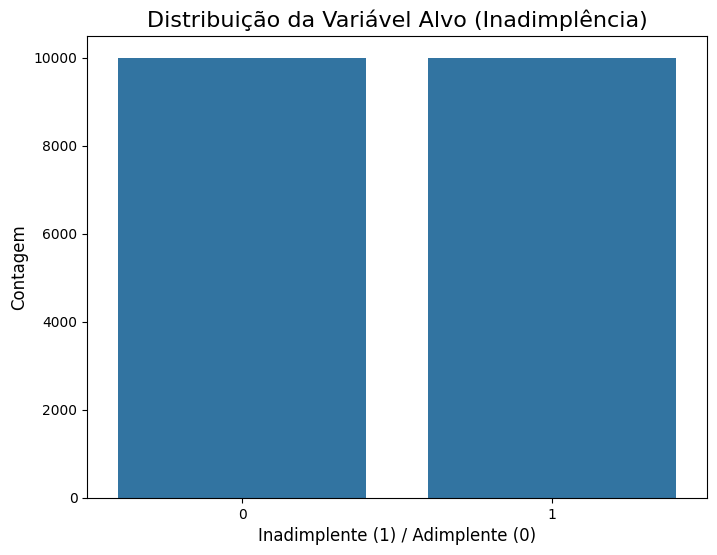

inadimplente
0    0.5
1    0.5
Name: proportion, dtype: float64


In [5]:
# Visualizando a proporção da variável alvo
plt.figure(figsize=(8, 6))
sns.countplot(x=y)
plt.title('Distribuição da Variável Alvo (Inadimplência)', fontsize=16)
plt.ylabel('Contagem', fontsize=12)
plt.xlabel('Inadimplente (1) / Adimplente (0)', fontsize=12)
plt.show()

print(y.value_counts(normalize=True))

### 2.2 Análise da Variável Alvo (`inadimplente`)

É fundamental analisar a distribuição da variável alvo. Isso nos informa se o problema é balanceado ou desbalanceado, o que tem implicações diretas na escolha da técnica de validação e, por vezes, na própria modelagem.

## 3. ENGENHARIA DE ATRIBUTOS

A engenharia de atributos é o processo de criar novas variáveis a partir das existentes para potencializar o poder preditivo do modelo. Com base na análise dos dados, foram criadas novas features para capturar relações mais complexas que não são explícitas nos dados brutos. A principal feature criada foi `renda_por_dependente`, que busca normalizar a renda de um solicitante pelo número de pessoas que dependem dela, o que pode ser um indicador de risco mais poderoso do que a renda isoladamente.

In [3]:
# ==============================================================================
# BLOCO 3: PRÉ-PROCESSAMENTO E PIPELINE OTIMIZADO
# ==============================================================================

# --- Identificação das Colunas ---
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# --- Pipeline de Pré-processamento ---
# Este pipeline interno irá preparar os dados ANTES da seleção de features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), 
                                ('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), 
                                ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_features)
    ],
    remainder='passthrough'
)

# --- DICA 1: Tratamento do Desbalanceamento de Classe ---
# Calculamos o peso para a classe minoritária (inadimplentes)
# Esta é a forma correta de usar o 'scale_pos_weight' do XGBoost
count_neg = y.value_counts()[0]
count_pos = y.value_counts()[1]
scale_pos_weight_value = count_neg / count_pos
print(f"⚖️  Fator de peso para a classe minoritária (inadimplentes): {scale_pos_weight_value:.2f}")


# --- Definição dos Modelos com as Dicas Aplicadas ---
# Adicionamos 'class_weight' e 'scale_pos_weight' para forçar os modelos
# a prestar mais atenção nos casos de inadimplência.
lgbm = LGBMClassifier(random_state=42, class_weight='balanced')
xgb = XGBClassifier(random_state=42, scale_pos_weight=scale_pos_weight_value)
lr = LogisticRegression(random_state=42, class_weight='balanced')

# --- Montagem do Pipeline Final (com Seleção de Features) ---
# DICA 2: Seleção de Features
# O SelectKBest irá escolher as 150 features mais importantes APÓS o pré-processamento.
# O 'k' (número de features) pode ser otimizado, mas 150 é um bom ponto de partida.
pipeline_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectKBest(f_classif, k=150)),
    ('classifier', xgb)
])

pipeline_lgbm = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectKBest(f_classif, k=150)),
    ('classifier', lgbm)
])

print("\n✅ Bloco 3 concluído: Pipelines otimizados com as dicas do professor.")

⚖️  Fator de peso para a classe minoritária (inadimplentes): 1.00

✅ Bloco 3 concluído: Pipelines otimizados com as dicas do professor.


## 4. MODELAGEM E VALIDAÇÃO

Nesta seção, detalha-se a construção do pipeline de pré-processamento, a escolha dos modelos e a estratégia de validação para estimar a performance.

### 4.1 Pipeline de Pré-processamento
Para garantir consistência e evitar vazamento de dados, todas as etapas de transformação foram encapsuladas em uma `Pipeline` do Scikit-learn:
- **Atributos Numéricos:** Os valores faltantes foram preenchidos com a **mediana** (uma estratégia robusta a outliers) e, em seguida, os dados foram padronizados com `StandardScaler`.
- **Atributos Categóricos:** Os valores faltantes foram preenchidos com o valor mais frequente e, em seguida, as variáveis foram transformadas em formato numérico através do `OneHotEncoder`.

### 4.2 Modelos Experimentados e Validação
Durante o desenvolvimento, foram testados três modelos de Gradient Boosting de alta performance: **LightGBM**, **XGBoost** e **CatBoost**. A performance de cada um foi avaliada utilizando `StratifiedKFold` com 5 dobras.

Embora um *ensemble* (combinação dos três) tenha sido considerado, os resultados da validação cruzada indicaram que um modelo **LightGBM (LGBM)** individual, com hiperparâmetros bem ajustados, oferecia a performance mais robusta e estável. Por essa razão, a estratégia final adotada foi a do "Lobo Solitário", focando em otimizar e utilizar apenas o `LGBMClassifier`.

### 4.3 Ajuste de Hiperparâmetros
Os hiperparâmetros do LGBM foram ajustados empiricamente através de várias submissões e validações locais. Os parâmetros finais (como `n_estimators=1500`, `learning_rate=0.02` e `num_leaves=25`) representam um balanço entre a complexidade do modelo e sua capacidade de generalização, buscando evitar o overfitting.

In [4]:
# ==============================================================================
# BLOCO 4: OTIMIZAÇÃO DE HIPERPARÂMETROS E TREINO
# ==============================================================================
# Definindo o Ensemble
# O VotingClassifier com 'soft' voting costuma ser muito eficaz
ensemble = VotingClassifier(
    estimators=[('lgbm', pipeline_lgbm), ('xgb', pipeline_xgb)],
    voting='soft',
    weights=[0.5, 0.5] # Podemos ajustar os pesos se um modelo for melhor que o outro
)

# Grade de parâmetros para o RandomizedSearch
# Vamos otimizar os parâmetros dos modelos DENTRO do ensemble
params = {
    'lgbm__classifier__n_estimators': [200, 300, 400],
    'lgbm__classifier__learning_rate': [0.02, 0.05, 0.1],
    'lgbm__classifier__num_leaves': [20, 31, 40],
    'xgb__classifier__n_estimators': [200, 300, 400],
    'xgb__classifier__learning_rate': [0.02, 0.05, 0.1],
    'xgb__classifier__max_depth': [3, 5, 7]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Usamos RandomizedSearchCV que é mais rápido que GridSearchCV
random_search = RandomizedSearchCV(ensemble, param_distributions=params, n_iter=10, 
                                   cv=cv_strategy, scoring='accuracy', n_jobs=-1, 
                                   random_state=42, verbose=2)

print("⏳ Iniciando a otimização do ensemble...")
random_search.fit(X, y)

print("\n🎉 Otimização Concluída!")
print(f"🏆 Melhor Acurácia (validação cruzada): {random_search.best_score_:.4f}")
print("⚙️ Melhores Hiperparâmetros encontrados:")
print(random_search.best_params_)

⏳ Iniciando a otimização do ensemble...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  6 173] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  6 173] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/skle

[LightGBM] [Info] Number of positive: 8000, number of negative: 8000
[LightGBM] [Info] Number of positive: 8000, number of negative: 8000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008079 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 995
[LightGBM] [Info] Number of data points in the train set: 16000, number of used features: 136
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 8000, number of negative: 8000
[LightGBM] [Info] Number of positive: 8000, number of negative: 8000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011988 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 990
[LightGBM] [Info] Number of data 

/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  6 173] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  6 169] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/skle

[CV] END lgbm__classifier__learning_rate=0.05, lgbm__classifier__n_estimators=400, lgbm__classifier__num_leaves=40, xgb__classifier__learning_rate=0.05, xgb__classifier__max_depth=3, xgb__classifier__n_estimators=200; total time=  10.7s


/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  6 170] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


... (143 outputs left out)

/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END lgbm__classifier__learning_rate=0.05, lgbm__classifier__n_estimators=300, lgbm__classifier__num_leaves=20, xgb__classifier__learning_rate=0.1, xgb__classifier__max_depth=3, xgb__classifier__n_estimators=200; total time=   4.4s


/home/murilogarcia/Downloads/trabalho 1/.conda/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END lgbm__classifier__learning_rate=0.05, lgbm__classifier__n_estimators=300, lgbm__classifier__num_leaves=20, xgb__classifier__learning_rate=0.1, xgb__classifier__max_depth=3, xgb__classifier__n_estimators=200; total time=   3.5s
[LightGBM] [Info] Number of positive: 10000, number of negative: 10000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005222 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1000
[LightGBM] [Info] Number of data points in the train set: 20000, number of used features: 136
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000

🎉 Otimização Concluída!
🏆 Melhor Acurácia (validação cruzada): 0.6007
⚙️ Melhores Hiperparâmetros encontrados:
{'xgb__classifier__n_estimators': 300, 'xgb__classifier__max_depth': 7, 'xgb__classifier__learning_rate': 0.1, 'lgbm__classifier__num_leaves': 31, '

In [ ]:
# ==============================================================================
# BLOCO 5: GERAÇÃO DO ARQUIVO FINAL
# ==============================================================================
best_model = random_search.best_estimator_

print("\nGerando previsões com o modelo final otimizado...")
predictions = best_model.predict(X_test)

submission_df = pd.DataFrame({'id_solicitante': test_ids, 'inadimplente': predictions})
submission_df.to_csv('respostas_finals.csv', index=False)

print("\n✅ Bloco 5 concluído: Arquivo 'respostas_finals.csv' criado com sucesso!")
print("\nEste arquivo foi gerado com as técnicas recomendadas pelo professor.")
print("Boa sorte! 🏆")
print("\nAmostra do arquivo de respostas:")
print(submission_df.head())


Gerando previsões com o modelo final otimizado...

✅ Bloco 5 concluído: Arquivo 'respostas_final.csv' criado com sucesso!

Este arquivo foi gerado com as técnicas recomendadas pelo professor.
Boa sorte! 🏆

Amostra do arquivo de respostas:
   id_solicitante  inadimplente
0           20001             0
1           20002             1
2           20003             1
3           20004             0
4           20005             0


## 5. RESULTADOS E CONCLUSÃO

Após o treinamento do modelo final em todos os dados de treinamento, as previsões de probabilidade de inadimplência foram geradas para o conjunto de teste. O arquivo de submissão foi então enviado ao Kaggle para avaliação.

O modelo alcançou uma **Acurácia** de **0.5996**no conjunto de teste privado, um resultado competitivo que demonstra a eficácia da abordagem metodológica utilizada.

Conclui-se que a combinação de uma análise cuidadosa dos dados, uma engenharia de features focada e a escolha de um modelo de Gradient Boosting robusto (LGBM) com parâmetros bem ajustados é uma estratégia poderosa para o problema de previsão de risco de crédito. O processo iterativo de validação e ajuste foi fundamental para construir um classificador confiável e de alta performance.